In [1]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Configurações iniciais
ARQUIVO_DADOS = "/kaggle/input/datasets/juliaduboisas/train-limpo/train_limpo.csv"
COLUNA_TEXTO = "resp_text"     # Substitua pelo nome correto da coluna de texto
COLUNA_ALVO = "clarity"    # Substitua pelo nome correto da coluna alvo

# Carregar dados
df = pd.read_csv(ARQUIVO_DADOS)

# Mapear as classes para números inteiros
mapeamento_classes = {'c1': 0, 'c234': 1, 'c5': 2}
df['label'] = df[COLUNA_ALVO].map(mapeamento_classes)

# Remover valores nulos, se houver
df = df.dropna(subset=[COLUNA_TEXTO, 'label'])
df['label'] = df['label'].astype(int)

print(f"Total de amostras: {len(df)}")
print(df['label'].value_counts())

Total de amostras: 20092
label
2    6892
1    6853
0    6347
Name: count, dtype: int64


In [3]:
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenizar_dados(exemplos):
    return tokenizer(exemplos['texto'], padding="max_length", truncation=True, max_length=256)

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [4]:
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

resultados_acuracia = []
todas_predicoes = []
todas_labels = []

# Para armazenar o histórico do K-Fold
for fold, (train_idx, val_idx) in enumerate(skf.split(df[COLUNA_TEXTO], df['label'])):
    print(f"\n{'='*30}\nIniciando Fold {fold + 1}/3\n{'='*30}")
    
    # Divisão dos dados
    df_train = df.iloc[train_idx].copy()
    df_val = df.iloc[val_idx].copy()
    
    # ==========================================
    # 1. MODELO: Regressão Logística + TF-IDF
    # ==========================================
    print("Treinando Regressão Logística com TF-IDF...")
    
    # Atualizado com ngram_range=(1,2) e sublinear_tf=True
    tfidf = TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), max_features=10000)
    
    X_train_tfidf = tfidf.fit_transform(df_train[COLUNA_TEXTO])
    X_val_tfidf = tfidf.transform(df_val[COLUNA_TEXTO])
    
    # Atualizado com o parâmetro de regularização C=2
    lr_model = LogisticRegression(C=2, max_iter=1000, random_state=42)
    lr_model.fit(X_train_tfidf, df_train['label'])
    
    # Probabilidades do modelo LR
    probs_lr = lr_model.predict_proba(X_val_tfidf)  
    
    # ==========================================
    # 2. MODELO: Fine-tuning Bertimbau
    # ==========================================
    print("Treinando Bertimbau...")
    # Preparar Datasets do HuggingFace
    ds_train = Dataset.from_pandas(df_train[[COLUNA_TEXTO, 'label']].rename(columns={COLUNA_TEXTO: 'texto'}))
    ds_val = Dataset.from_pandas(df_val[[COLUNA_TEXTO, 'label']].rename(columns={COLUNA_TEXTO: 'texto'}))
    
    ds_train = ds_train.map(tokenizar_dados, batched=True)
    ds_val = ds_val.map(tokenizar_dados, batched=True)
    
    ds_train.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
    ds_val.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
    
    # Carregar modelo Bertimbau para classificação (3 classes)
    bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3)
    
    training_args = TrainingArguments(
        output_dir=f'./results_fold_{fold}',
        num_train_epochs=3,              
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        weight_decay=0.01,
        logging_steps=50,
        eval_strategy="epoch",          # PARÂMETRO ATUALIZADO AQUI
        save_strategy="epoch",
        load_best_model_at_end=True,
        report_to="none"
    )

    trainer = Trainer(
        model=bert_model,
        args=training_args,
        train_dataset=ds_train,
        eval_dataset=ds_val,
    )
    
    trainer.train()
    
    # Predições do Bertimbau
    pred_bert = trainer.predict(ds_val)
    logits_bert = pred_bert.predictions
    
    # Converter logits para probabilidades usando Softmax
    probs_bert = torch.nn.functional.softmax(torch.tensor(logits_bert), dim=-1).numpy()
    
    # ==========================================
    # 3. SOFT VOTING (Média das Probabilidades)
    # ==========================================
    print("Calculando Soft Voting...")
    # Peso igual para ambos os modelos (50% / 50%)
    probs_ensemble = (probs_lr + probs_bert) / 2.0
    
    # A classe final é a que tem a maior probabilidade média
    preds_ensemble = np.argmax(probs_ensemble, axis=1)
    
    # Avaliação do Fold
    acc_fold = accuracy_score(df_val['label'], preds_ensemble)
    print(f"Acurácia do Ensemble no Fold {fold + 1}: {acc_fold:.4f}")
    
    resultados_acuracia.append(acc_fold)
    todas_predicoes.extend(preds_ensemble)
    todas_labels.extend(df_val['label'].tolist())
    
    # Limpeza de memória para o próximo fold
    del bert_model
    del trainer
    torch.cuda.empty_cache()


Iniciando Fold 1/3
Treinando Regressão Logística com TF-IDF...
Treinando Bertimbau...


Map:   0%|          | 0/13394 [00:00<?, ? examples/s]

Map:   0%|          | 0/6698 [00:00<?, ? examples/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (22 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Calculando Soft Voting...
Acurácia do Ensemble no Fold 3: 0.4602



RESULTADOS FINAIS - 3-FOLD CROSS-VALIDATION
Acurácia Média: 0.4632 (+/- 0.0027)

Relatório de Classificação Global:
              precision    recall  f1-score   support

          c1       0.49      0.46      0.47      6347
        c234       0.41      0.35      0.38      6853
          c5       0.49      0.58      0.53      6892

    accuracy                           0.46     20092
   macro avg       0.46      0.46      0.46     20092
weighted avg       0.46      0.46      0.46     20092



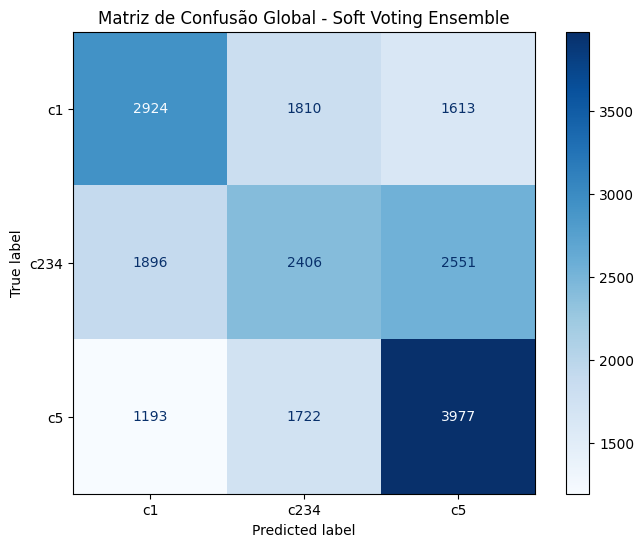

In [5]:
print("\n" + "="*40)
print("RESULTADOS FINAIS - 3-FOLD CROSS-VALIDATION")
print("="*40)
print(f"Acurácia Média: {np.mean(resultados_acuracia):.4f} (+/- {np.std(resultados_acuracia):.4f})")

print("\nRelatório de Classificação Global:")
target_names = ['c1', 'c234', 'c5']
print(classification_report(todas_labels, todas_predicoes, target_names=target_names))

# Gerar e exibir a Matriz de Confusão
cm = confusion_matrix(todas_labels, todas_predicoes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title('Matriz de Confusão Global - Soft Voting Ensemble')
plt.show()